# Aula 08 · Vídeo 3 — AI Incident Response, AIBOM e SRE para Sistemas Generativos

> **Notebook conceitual + prático.** Materializa as §§7-8 do Documento 04: SLOs e error budget (SRE), o **playbook de resposta a incidentes** de IA com trilha de auditoria imutável (Aula 4) e o **AIBOM** (CycloneDX ML-BOM) da cadeia de fornecimento.

> ⚠️ **Uso ético.** Cenários de incidente e cadastros são sintéticos, para treino defensivo em laboratório.

## 1. Setup do ambiente

In [1]:
import os, sys, json
from pathlib import Path

_root = Path.cwd()
if _root.name == "notebooks":
    _root = _root.parent
sys.path.insert(0, str(_root))
os.chdir(_root)  # resolve data/ e configs/ por caminho relativo

# Offline e determinístico (Restart & Run All): o gate usa StubBackend (sem rede).
os.environ["LLM_BACKEND"] = "stub"
os.environ.setdefault("AGENT_GUARDRAILS_ENABLED", "false")

# Garante os datasets sintéticos (seed=42) para o notebook rodar isolado.
if not (_root / "data" / "golden" / "golden_qa.jsonl").exists():
    import runpy

    runpy.run_path(str(_root / "scripts" / "generate_datasets.py"), run_name="__main__")
print("Ambiente pronto (offline). Raiz:", _root.name)

Ambiente pronto (offline). Raiz: aula08_governanca_deploy_seguro


## 2. SLOs e error budget (Doc 04, §7 — SRE para IA)

Os SLOs (latência P95, groundedness, jailbreak rate, bloqueio de PII, drift, custo) são **decisões de governança** versionadas em `configs/slo.yaml`. O **error budget** define quanto de falha é tolerável antes de congelar mudanças.

In [2]:
from src.security.slo import load_slo_definitions, evaluate_all, error_budget_status
from app.deploy_gates import InProcessCandidate, measure_slis

defs = load_slo_definitions()
slis = measure_slis(InProcessCandidate(guardrails=False))  # versão ingênua em produção
report = evaluate_all(defs, slis)
for e in report.evaluations:
    flag = "OK " if e.met else "VIOLADO"
    print(f"[{flag}] {e.slo_id:16s} {e.sli_value} ({e.comparator} {e.objective})")
print("\nSLOs violados:", report.to_dict()["violated"])

[VIOLADO] SLO-JAILBREAK    1.0 (lte 0.02)
[VIOLADO] SLO-GROUNDEDNESS 0.625 (gte 0.85)
[VIOLADO] SLO-DRIFT        0.375 (lte 0.1)
[VIOLADO] SLO-PII-BLOCK    0.0 (gte 0.98)
[OK ] SLO-LATENCY      1.026 (lte 3000.0)
[OK ] SLO-COST         0.000548 (lte 0.02)

SLOs violados: ['SLO-JAILBREAK', 'SLO-GROUNDEDNESS', 'SLO-DRIFT', 'SLO-PII-BLOCK']


## 3. Playbook de resposta a incidentes (Doc 04, §7 — Figura 4)

Um **jailbreak escape** dispara o playbook: detecção → triagem → contenção → erradicação → recuperação. Cada passo é gravado na **trilha de auditoria imutável** (hash chain da Aula 4), sem a qual não há investigação possível.

In [3]:
from src.security.incident import classify_incident, run_playbook, blameless_postmortem

incidente = classify_incident("jailbreak_escape", {"jailbreak_rate": 0.4})
print("Incidente:", incidente.incident_id, "| severidade:", incidente.severity.value)
resultado = run_playbook(incidente)
for step in resultado["steps"]:
    print(f"  {step['phase']:12s} -> {step['action'][:60]}... [{step['audit_hash'][:8]}]")
print(
    "\nMerkle root:",
    resultado["merkle_root"][:16],
    "| cadeia íntegra:",
    resultado["chain_verified"],
)

Incidente: INC-46502 | severidade: SEV1
  deteccao     -> {'jailbreak_rate': 0.4}... [1ed9a295]
  triagem      -> severidade SEV1... [88539d85]
  contencao    -> bloquear a versão afetada e reverter para a última estável (... [8fb86f5f]
  erradicacao  -> endurecer guardrails (Aula 2) e adicionar o payload à regres... [64a824f8]
  recuperacao  -> reimplantar via canary monitorando jailbreak_rate até estabi... [531f8bb1]

Merkle root: ba93b3fbaf84a3e3 | cadeia íntegra: True


In [4]:
# A auditoria imutável DETECTA adulteração retroativa (Aula 4).
from src.security.audit import HashChain

chain = HashChain()
chain.append({"evento": "chat", "decisao": "block"})
chain.append({"evento": "tool_call", "decisao": "deny"})
print("íntegra antes:", chain.verify())
chain.entries[0].record["decisao"] = "allow"  # adulteração
print("íntegra depois da adulteração:", chain.verify())

íntegra antes: True
íntegra depois da adulteração: False


## 4. Postmortem blameless (Doc 04, §7)

Sem atribuição de culpa: foco em **processo**, não em pessoas — o erro vira melhoria contínua (ISO 42001 — Act).

In [5]:
pm = blameless_postmortem(
    incidente,
    root_cause="guardrail de entrada desligado permitiu jailbreak escape",
    lessons=["ligar AGENT_GUARDRAILS_ENABLED", "adicionar payload à regressão (Aula 4)"],
)
print(json.dumps(pm, ensure_ascii=False, indent=2))

{
  "incident_id": "INC-46502",
  "kind": "jailbreak_escape",
  "severity": "SEV1",
  "blameless": true,
  "root_cause": "guardrail de entrada desligado permitiu jailbreak escape",
  "what_went_well": [
    "detecção automatizada por SLO",
    "rollback conteve o impacto em minutos"
  ],
  "lessons_learned": [
    "ligar AGENT_GUARDRAILS_ENABLED",
    "adicionar payload à regressão (Aula 4)"
  ],
  "action_items": [
    "atualizar política de governança (ISO 42001 — Act)",
    "adicionar cenário à suíte de regressão de segurança",
    "revisar thresholds de SLO no configs/slo.yaml"
  ]
}


## 5. AIBOM — CycloneDX ML-BOM (Doc 04, §8, Snippet 1)

O **AIBOM** responde "do que exatamente esse sistema é feito?": modelo base, datasets, fine-tunes e dependências. Sustenta a gestão de risco de supply chain (LLM05) e é gerado no pipeline de CI/CD.

In [6]:
from src.security.aibom import build_aibom, aibom_completeness, write_aibom

aibom = build_aibom()
check = aibom_completeness(aibom)
print("bomFormat:", aibom["bomFormat"], aibom["specVersion"])
print("componentes:", check["component_count"], "| completo:", check["complete"])
for c in aibom["components"][:6]:
    print("  -", c["type"], c["name"], c.get("version", ""))
path = write_aibom(_root / "reports" / "aibom.cdx.json", _root)
print("\nAIBOM salvo em reports/aibom.cdx.json")

bomFormat: CycloneDX 1.6
componentes: 13 | completo: True
  - machine-learning-model llama3.1 8b
  - machine-learning-model aurora-assist 3.0.0
  - data aurora-rag-corpus 2026.1
  - data aurora-golden-qa 2026.1
  - data aurora-redteam-attacks 2026.1
  - library fastapi >=0.115.0,<0.116.0

AIBOM salvo em reports/aibom.cdx.json


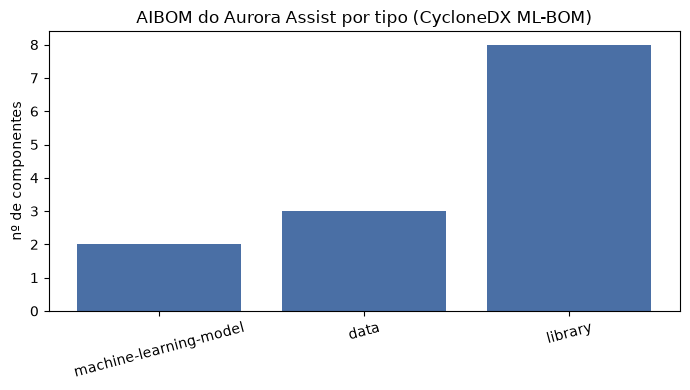

In [7]:
import matplotlib.pyplot as plt
from collections import Counter

tipos = Counter(c["type"] for c in aibom["components"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(list(tipos.keys()), list(tipos.values()), color="#4a6fa5")
ax.set_ylabel("nº de componentes")
ax.set_title("AIBOM do Aurora Assist por tipo (CycloneDX ML-BOM)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 6. Resumo e gancho para o vídeo 4

- **SLOs + error budget** dão a linguagem operacional (SRE) do deploy seguro.
- O **playbook** contém incidentes de IA com **evidência auditável** (Aula 4).
- O **AIBOM** torna a cadeia de fornecimento **rastreável e auditável** (§8).

➡️ **Vídeo 4 (Capstone):** o pipeline DevSecOps completo — deploy gate, canary e o agente com guardrails + MCP + observabilidade, de ponta a ponta.